In [1]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


In [2]:

from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Classes:", iris.target_names)


Dataset Shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [3]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [4]:

import torch

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Data is ready!")
print("Training shape:", X_train.shape)


Data is ready!
Training shape: torch.Size([120, 4])


In [5]:

import torch.nn as nn

class SoftDecisionTree(nn.Module):
    def __init__(self, input_size=4, num_classes=3):
        super().__init__()

        self.decision = nn.Linear(input_size, 1)
        self.leaves = nn.Parameter(torch.randn(2, num_classes) * 0.1)

    def forward(self, x):
        p = torch.sigmoid(self.decision(x))

        left = torch.softmax(self.leaves[0], dim=0)
        right = torch.softmax(self.leaves[1], dim=0)

        return (1 - p) * left + p * right


class DifferentiableRandomForest(nn.Module):
    def __init__(self, num_trees=10):
        super().__init__()

        self.trees = nn.ModuleList([
            SoftDecisionTree() for _ in range(num_trees)
        ])

    def forward(self, x):
        predictions = [tree(x) for tree in self.trees]
        return torch.stack(predictions).mean(dim=0)

torch.manual_seed(42)

model = DifferentiableRandomForest(num_trees=10)

print("Model created successfully!")


Model created successfully!


In [6]:

import torch.optim as optim

criterion = nn.NLLLoss()

optimizer = optim.SGD(model.parameters(), lr=0.5)

losses = []

for epoch in range(1000):
    optimizer.zero_grad()

    outputs = model(X_train)

    loss = criterion(torch.log(outputs.clamp(min=1e-8)), y_train)

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")


Epoch 20, Loss: 1.0880
Epoch 40, Loss: 1.0760
Epoch 60, Loss: 1.0600
Epoch 80, Loss: 1.0390
Epoch 100, Loss: 1.0136
Epoch 120, Loss: 0.9853
Epoch 140, Loss: 0.9557
Epoch 160, Loss: 0.9263
Epoch 180, Loss: 0.8979
Epoch 200, Loss: 0.8710
Epoch 220, Loss: 0.8459
Epoch 240, Loss: 0.8227
Epoch 260, Loss: 0.8012
Epoch 280, Loss: 0.7815
Epoch 300, Loss: 0.7633
Epoch 320, Loss: 0.7466
Epoch 340, Loss: 0.7311
Epoch 360, Loss: 0.7169
Epoch 380, Loss: 0.7037
Epoch 400, Loss: 0.6915
Epoch 420, Loss: 0.6801
Epoch 440, Loss: 0.6695
Epoch 460, Loss: 0.6597
Epoch 480, Loss: 0.6504
Epoch 500, Loss: 0.6418
Epoch 520, Loss: 0.6337
Epoch 540, Loss: 0.6261
Epoch 560, Loss: 0.6189
Epoch 580, Loss: 0.6122
Epoch 600, Loss: 0.6058
Epoch 620, Loss: 0.5998
Epoch 640, Loss: 0.5942
Epoch 660, Loss: 0.5888
Epoch 680, Loss: 0.5838
Epoch 700, Loss: 0.5790
Epoch 720, Loss: 0.5745
Epoch 740, Loss: 0.5702
Epoch 760, Loss: 0.5662
Epoch 780, Loss: 0.5623
Epoch 800, Loss: 0.5587
Epoch 820, Loss: 0.5553
Epoch 840, Loss: 0.5

In [7]:

from sklearn.metrics import accuracy_score

model.eval()

with torch.no_grad():
    outputs = model(X_test)
    predictions = torch.argmax(outputs, dim=1)

accuracy = accuracy_score(y_test.numpy(), predictions.numpy())

print(f"GD Accuracy: {accuracy * 100:.2f}%")


GD Accuracy: 80.00%


In [8]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test.numpy(), predictions.numpy())

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[10  0  0]
 [ 0  5  5]
 [ 0  1  9]]


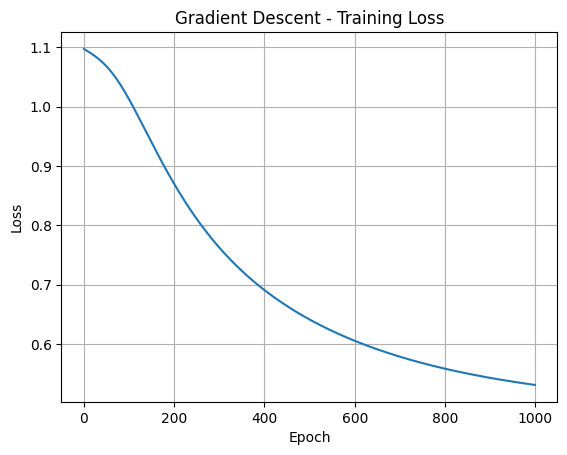

In [9]:

import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gradient Descent - Training Loss")
plt.grid(True)
plt.show()
